# Seven Simple Models of the Quinoa Boom

### An introduction to modeling for computational social science

---

This notebook is built around a single piece of journalism:

> Jeremy Cherfas, *"Your Quinoa Habit Really Did Help Peru's Poor. But There's Trouble Ahead,"* NPR (The Salt), 31 March 2016.
> https://www.npr.org/sections/thesalt/2016/03/31/472453674/your-quinoa-habit-really-did-help-perus-poor-but-theres-trouble-ahead

**The story in brief.** Between 2006 and 2013 the world price of quinoa roughly tripled as North American and European shoppers discovered it. Journalists warned that Andean farmers were being priced out of their own food. Economists then went to the data (ENAHO, Peru's annual household survey of about 22,000 households) and found the warning was wrong: quinoa growers gained the most, urban buyers absorbed a small extra cost, and nobody's nutrition measurably worsened. But the article ends on three warnings: farmers abandoned most of the ~3,000 quinoa varieties, soil is degrading, and after February 2014 the price fell as fast as it had risen.

**Why this article and not a dataset?** Because it is full of *verbal models*. Every claim in it is a compressed causal story:
* "growers benefit"
* "high prices attract competitors"
* "soil is getting worse"

A model is what you get when you make such a story precise enough to be wrong.

---

## How to read this notebook if you don't write code

You do not need to program to follow this. Read it like a set of illustrated arguments:

1. Read the **plain-language section** that opens each model. It states the claim from the article and the idea behind the model.
2. Skim the **code cell**. Every line has a comment. The code is deliberately slow and repetitive — written to be read, not to be efficient.
3. Look at the **picture** the code produces.
4. Read **"What to notice"** and try one of the **exercises**, which mostly mean changing a single number and re-running.

A few pieces of vocabulary, once:

- A **variable** is a name for a number: `price = 2.0` means "from now on, `price` refers to 2.0".
- A **list** or **array** is a named row of numbers, e.g. one value per year.
- A **loop** (`for year in years:`) means "do the following once for each year".
- A **function** (`def welfare(...)`) is a named recipe you can re-use with different inputs.
- A **parameter** is a number you choose that encodes an assumption. Parameters are where the modeling actually happens, and they are the honest place to argue.

**To run a cell:** click it and press `Shift+Enter`. Run the cells in order — later ones depend on earlier ones. The next cell loads the two tools we use throughout: `numpy` for arithmetic on rows of numbers, and `matplotlib` for pictures.

---

## A note about all the numbers below

* The *structures* of these models are taken seriously.
* The *numbers* are illustrative, chosen so the pictures are legible and roughly consistent with the magnitudes quoted in the article.
* None of this is a replication of the underlying papers by Bellemare, Gitter and Fajardo-Gonzalez, or by Stevens.
* Treat every result as "here is what would follow **if** the world worked like this," never as an estimate of what actually happened.

In [2]:
# ---------------------------------------------------------------------------
# SETUP. Run this cell first. It only has to run once.
# ---------------------------------------------------------------------------

# "import" loads a toolbox. "as np" gives it a short nickname so we can type
# np.array(...) instead of numpy.array(...).
import numpy as np                 # arithmetic on whole rows of numbers at once
import matplotlib.pyplot as plt    # drawing figures

# A few cosmetic defaults so every figure in the notebook looks the same.
plt.rcParams["figure.figsize"] = (9, 4.5)   # width, height in inches
plt.rcParams["axes.grid"] = True            # draw faint gridlines
plt.rcParams["grid.alpha"] = 0.3            # ...but keep them faint
plt.rcParams["font.size"] = 11

# A fixed "seed" for the random-number generator. Some models below use
# randomness; setting the seed means the random numbers are the SAME every time
# you run the notebook, so your figures match this text. Reproducibility is a
# methodological requirement, not a convenience.
RNG = np.random.default_rng(seed=20160331)

print("Setup complete. numpy version:", np.__version__)

Setup complete. numpy version: 2.4.6


# Model 1
# The one-line model: who gains when a price rises?

## The claim in the article

The economist Marc Bellemare says he was not surprised by the finding, because in the short run someone who sells more of a good than they buy is better off when its price goes up.

That sentence is a model. It has structure, it makes a prediction, and it can be checked. Let us write it down.

## The idea

Think of a household as doing two things with quinoa: **producing** some quantity (call it $q_{prod}$, in kilograms per year) and **consuming** some quantity ($q_{cons}$). The difference is what it trades:

$$\text{net sales} = q_{prod} - q_{cons}$$

If that number is positive the household is a **net seller**; if negative, a **net buyer**. Now let the price rise by $\Delta p$ soles per kilogram. To a first approximation, the change in the household's real income is

$$\boxed{\Delta W \;\approx\; (q_{prod} - q_{cons}) \times \Delta p}$$

That is the whole model. No computer required — but a computer makes it easy to vary the assumptions.

## Why "approximately"?

Because the household will *respond* to the new price: grow a bit more quinoa, eat a bit less, switch some spending. Those responses make the true gain slightly larger than the formula says for sellers, and the true loss slightly smaller for buyers. The formula is the value of the *first* step, before anyone adjusts. Economists call this a first-order approximation; in more advanced courses it appears as the envelope theorem. For our purposes: it is accurate for small price changes and gets rougher as the change gets large — and a tripling is not small. Hold that thought; it comes back in the discussion.

## The households

The article gives us enough to sketch three types. We use per-household figures for a household of four.

| Type | Where | Produces | Eats | Budget |
|---|---|---|---|---|
| Grower-eater | Puno | yes | yes | poorer |
| Eater only | Lima etc. | no | yes | about twice as well off |
| Neither | Peru | no | no | — |

Two anchors from the article: quinoa is under **4%** of the household budget in Puno and under **0.5%** elsewhere; people in Puno ate about **22 kg per person per year** against a national average of about **6 kg**.

In [4]:
# ---------------------------------------------------------------------------
# MODEL 1: net-seller welfare arithmetic
# ---------------------------------------------------------------------------

# --- Assumptions (all the modeling lives here) ------------------------------
PRICE_BEFORE = 2.0    # soles per kilogram, before the boom
PRICE_AFTER  = 6.0    # soles per kilogram, after the tripling described in the article
PEOPLE       = 4      # people per household

# Quinoa eaten per person per year, in kilograms (figures quoted in the article).
EAT_PUNO_PP     = 22.2
EAT_NATIONAL_PP = 6.1

# Turn per-person eating into per-household eating.
eat_puno     = EAT_PUNO_PP * PEOPLE       # about 89 kg per household per year
eat_national = EAT_NATIONAL_PP * PEOPLE   # about 24 kg per household per year

# We can BACK OUT each household's total budget from the budget shares in the
# article. If quinoa costs (eat x price) and that is 4% of the budget, then the
# budget must be (eat x price) / 0.04. This is a nice habit to notice: a share
# plus a level gives you the whole.
budget_puno     = (eat_puno * PRICE_BEFORE) / 0.040       # Puno: under 4% of budget
budget_national = (eat_national * PRICE_BEFORE) / 0.005    # elsewhere: under 0.5%

# How much a Puno grower harvests per year. This is the least well-anchored
# number in the model, so we will test how much it matters afterwards.
GROW_PUNO = 400.0     # kilograms per household per year

# --- The three household types, as a plain list of dictionaries -------------
# A "dictionary" is a labelled bundle of numbers: name, production, consumption, budget.
households = [
    {"name": "Grower-eater (Puno)",  "produces": GROW_PUNO, "eats": eat_puno,     "budget": budget_puno},
    {"name": "Eater only (urban)",   "produces": 0.0,       "eats": eat_national, "budget": budget_national},
    {"name": "Neither",              "produces": 0.0,       "eats": 0.0,          "budget": budget_national},
]

# --- The model itself: three lines ------------------------------------------
def welfare_change(produces, eats, price_change):
    # Net sales are what you grow minus what you eat. Positive = you are a seller.
    net_sales = produces - eats
    # The gain (or loss) is net sales multiplied by how much the price moved.
    return net_sales * price_change

price_change = PRICE_AFTER - PRICE_BEFORE   # +4 soles per kilogram

print("Price rises from %.1f to %.1f soles/kg  (a change of %+.1f)\n" % (PRICE_BEFORE, PRICE_AFTER, price_change))
print("%-22s %10s %10s %10s %12s %10s" % ("household", "grows", "eats", "net sales", "gain (soles)", "% budget"))
print("-" * 80)

results = []   # we save the answers so we can plot them in the next cell
for h in households:
    gain = welfare_change(h["produces"], h["eats"], price_change)
    pct  = 100.0 * gain / h["budget"]         # express the gain as a share of the budget
    results.append((h["name"], gain, pct))
    print("%-22s %10.0f %10.0f %10.0f %12.0f %+10.1f" % (
        h["name"], h["produces"], h["eats"], h["produces"] - h["eats"], gain, pct))

Price rises from 2.0 to 6.0 soles/kg  (a change of +4.0)

household                   grows       eats  net sales gain (soles)   % budget
--------------------------------------------------------------------------------
Grower-eater (Puno)           400         89        311         1245      +28.0
Eater only (urban)              0         24        -24          -98       -1.0
Neither                         0          0          0            0       +0.0


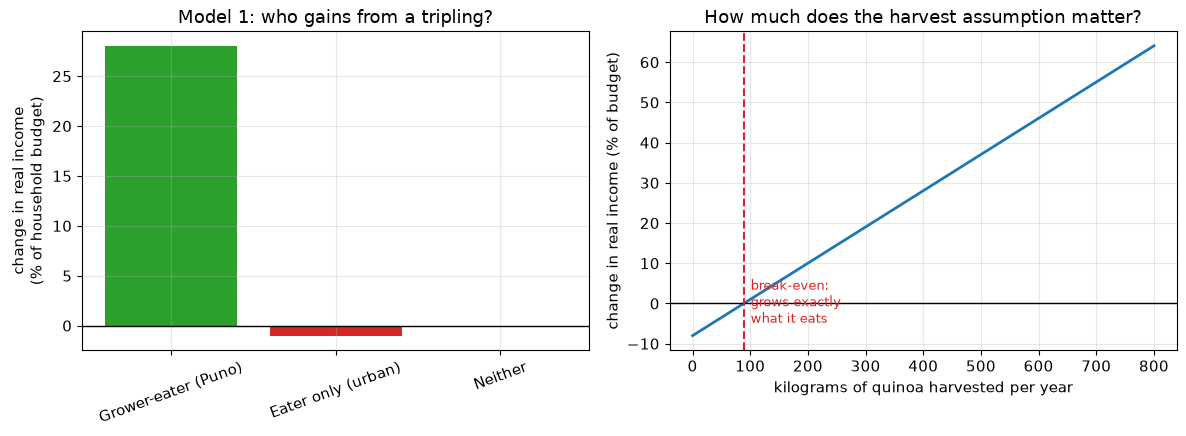

In [5]:
# ---------------------------------------------------------------------------
# Picture it, and then ask how much the shakiest assumption matters.
# ---------------------------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Left panel: the gain for each household type, as % of its budget 
names = [r[0] for r in results] # pull the names out of our saved results
pcts  = [r[2] for r in results] # ...and the percentages
colours = ["tab:green" if p > 0 else "tab:red" if p < 0 else "tab:grey" for p in pcts]

ax1.bar(names, pcts, color=colours)
ax1.axhline(0, color="black", linewidth=1) # a line at zero, for reference
ax1.set_ylabel("change in real income\n(% of household budget)")
ax1.set_title("Model 1: who gains from a tripling?")
ax1.tick_params(axis="x", labelrotation=20)

# Right panel: SENSITIVITY ANALYSIS 
# We were unsure about how much a grower harvests. So instead of picking one
# number, try MANY and see what the model says for each. This is one of the most
# useful habits in modeling: never defend a number you can vary.
harvests = np.linspace(0, 800, 200)             # 200 evenly spaced values from 0 to 800 kg
gains_pct = 100.0 * welfare_change(harvests, eat_puno, price_change) / budget_puno

ax2.plot(harvests, gains_pct, linewidth=2)
ax2.axhline(0, color="black", linewidth=1)
ax2.axvline(eat_puno, color="tab:red", linestyle="--")
ax2.text(eat_puno + 12, gains_pct.min() * 0.6,
         "break-even:\ngrows exactly\nwhat it eats", color="tab:red", fontsize=9)
ax2.set_xlabel("kilograms of quinoa harvested per year")
ax2.set_ylabel("change in real income (% of budget)")
ax2.set_title("How much does the harvest assumption matter?")

plt.tight_layout()
plt.show()

## What to notice

**The sign of the effect does not depend on any hard-to-measure number.** It depends only on whether the household grows more than it eats. Everything else — the budget, the exact price, the elasticity of anything — affects the *size* of the answer, not its direction. That is a remarkably strong conclusion from a remarkably weak model, and it is why Bellemare could say he was unsurprised before seeing the data.

**The loss for buyers is small because the budget share is small.** This is the quiet workhorse of the whole argument. Quinoa is culturally central in Puno but it is not rice: under 4% of the budget there, under 0.5% elsewhere. A tripling of a 0.5% budget item costs you about 1% of your budget. You cannot get a humanitarian catastrophe out of a line item that small — which is the arithmetic the original scare stories skipped.

**The model over-predicts the gain, and knowing why is the point.** Our grower's gain comes out implausibly large as a share of its budget. At least four reasons, each a modeling lesson:

1. **A tripling is not a small change**, so the first-order approximation is being used far outside its comfort zone.
2. **Farm-gate prices are not world prices.** Traders, processors and exporters capture part of the rise, so the $\Delta p$ facing the farmer is smaller than the one facing the shopper.
3. **Quinoa is not the household's only income**, so its budget denominator should include other crops, livestock and wage work.
4. **The relevant comparison is against what else the land would have grown.** Switching land into quinoa means giving up something, and the model silently prices that at zero.

Each fix makes the model bigger. Deciding which fixes are worth the complication *is* the craft.

## Exercises

1. Set `GROW_PUNO = 60`. The household still grows less than it eats — now it is a net buyer despite being a farmer. What happens to the sign? Which real households does this describe?
2. Change `PRICE_AFTER` to 8.0 (a quadrupling, as the article reports for Puno). Do any conclusions change qualitatively, or only in magnitude? Why does that distinction matter when you report results?
3. The model has no time in it. Write down, in words, one thing that happens over five years that this model must be getting wrong. (Then read Model 2.)

---
# Model 2 
# Why farm prices overshoot: the cobweb

## The claim in the article

The price started falling in February 2014 and dropped about as fast as it had climbed, which the article treats as unsurprising: high prices attract competitors.

Model 1 cannot produce that. It has no time in it: prices are just given. To get a *boom followed by a bust* we need our first **dynamic** model — one where this year's outcome depends on last year's.

## The idea

Agriculture has an unavoidable delay. A farmer decides in the spring how much to plant, and finds out at harvest what the price is. So the plausible assumption is that planting responds to **last year's** price:

$$
\begin{aligned}
\text{how much is grown this year:} && Q^{S}_{t} &= c + d\, p_{t-1} \\
\text{how much people want to buy:} && Q^{D}_{t} &= a - b\, p_{t}
\end{aligned}
$$

Here $a, b, c, d$ are positive parameters: $b$ says how strongly buyers back off when the price rises, $d$ says how strongly farmers plant more when the price was high.

Once the crop is in, the harvest is fixed and the price must move until the market clears, $Q^{D}_{t} = Q^{S}_{t}$. Solving for this year's price:

$$\boxed{p_{t} = \frac{a - c - d\,p_{t-1}}{b}}$$

Read the minus sign in front of $d$: **a high price last year means a low price this year.** Farmers responding sensibly to yesterday's news generate oscillation. Nobody has to be irrational.

## The one thing worth remembering

Because each year's price is $-d/b$ times the last one (plus a constant), the behaviour depends entirely on the ratio $d/b$:

- $d/b < 1$ — oscillations **shrink**; the market settles down.
- $d/b = 1$ — oscillations **persist** forever, unchanged.
- $d/b > 1$ — oscillations **grow**; the market flies apart.

This is called a cobweb model, because of the shape it traces on a supply-and-demand diagram. It is one of the oldest formal models in economics, and it is the cleanest possible illustration of a general lesson: **delay plus negative feedback equals oscillation.** You will meet that lesson again in epidemics, in traffic, in inventory management, and in your own thermostat.

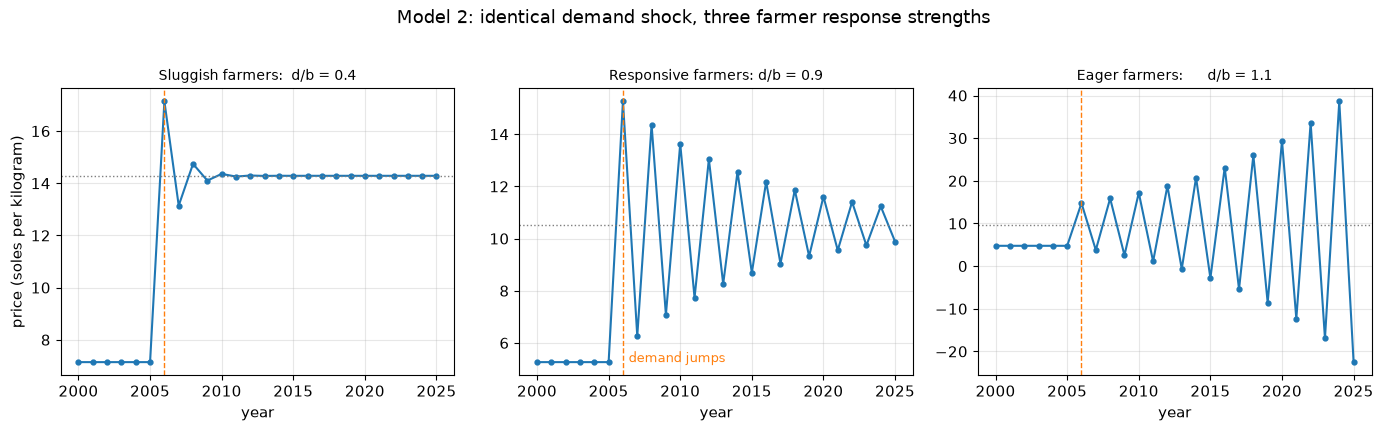

Dotted grey line = the price a delay-free market would settle at.
Note that all three panels have the same shock. Only d/b differs.


In [6]:
# ---------------------------------------------------------------------------
# MODEL 2: the cobweb. A one-off jump in demand, three different farmer types.
# ---------------------------------------------------------------------------

years = np.arange(2000, 2026)      # a row of years: 2000, 2001, ... 2025

# Parameters 
DEMAND_SLOPE      = 8.0     # "b": how much less is bought when the price rises by 1
SUPPLY_INTERCEPT  = 20.0    # "c": how much is grown even at a price of zero
DEMAND_BASE       = 100.0   # "a" before the world discovered quinoa
DEMAND_JUMP       = 80.0    # how much "a" rises when it becomes a superfood
BOOM_YEAR         = 2006    # the year the jump happens

def demand_intercept(year):
    # A single permanent step up in demand. Before BOOM_YEAR, the old world;
    # from BOOM_YEAR on, the new one. ("if/else" = "in this case / otherwise".)
    if year < BOOM_YEAR:
        return DEMAND_BASE
    else:
        return DEMAND_BASE + DEMAND_JUMP

def simulate_cobweb(supply_slope):
    # supply_slope is "d": how strongly farmers respond to last year's price.
    b, c, d = DEMAND_SLOPE, SUPPLY_INTERCEPT, supply_slope

    # Start the simulation at the calm long-run price of the OLD world, so that
    # anything interesting we see afterwards was caused by the demand jump and
    # not by an arbitrary starting point.
    prices = [(DEMAND_BASE - c) / (b + d)]

    # Now step forward one year at a time. Each new price is computed from the
    # previous one using the boxed formula above.
    for year in years[1:]:
        a = demand_intercept(year)
        previous_price = prices[-1]              # "[-1]" means "the last one so far"
        new_price = (a - c - d * previous_price) / b
        prices.append(new_price)

    return np.array(prices)

# Run the same model three times with three different farmer responses 
scenarios = [
    ("Sluggish farmers:  d/b = 0.4", 3.2),
    ("Responsive farmers: d/b = 0.9", 7.2),
    ("Eager farmers:      d/b = 1.1", 8.8),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)

for ax, (label, d) in zip(axes, scenarios):
    prices = simulate_cobweb(d)
    ax.plot(years, prices, marker="o", markersize=3.5, linewidth=1.5)
    ax.axvline(BOOM_YEAR, color="tab:orange", linestyle="--", linewidth=1)
    # The price the market would eventually reach if there were no delay at all:
    long_run = (DEMAND_BASE + DEMAND_JUMP - SUPPLY_INTERCEPT) / (DEMAND_SLOPE + d)
    ax.axhline(long_run, color="tab:grey", linestyle=":", linewidth=1)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("year")

axes[0].set_ylabel("price (soles per kilogram)")
axes[1].text(BOOM_YEAR + 0.4, axes[1].get_ylim()[0] + 0.5, "demand jumps", color="tab:orange", fontsize=9)
plt.suptitle("Model 2: identical demand shock, three farmer response strengths", y=1.02)
plt.tight_layout()
plt.show()

print("Dotted grey line = the price a delay-free market would settle at.")
print("Note that all three panels have the same shock. Only d/b differs.")

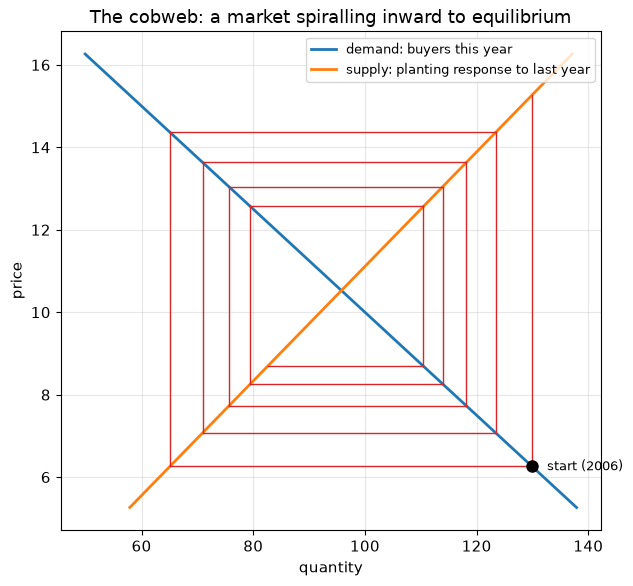

In [7]:
# ---------------------------------------------------------------------------
# Why it is called a "cobweb": the same simulation drawn on a supply-and-demand
# diagram instead of against time.
# ---------------------------------------------------------------------------

d = 7.2 # the "responsive farmers" case
prices = simulate_cobweb(d)

# Look only at the years after the shock, when the interesting adjustment happens.
start = list(years).index(BOOM_YEAR)
p_path = prices[start:start + 10]
a_new = DEMAND_BASE + DEMAND_JUMP

fig, ax = plt.subplots(figsize=(6.5, 6))

# Draw the two curves. (They are straight lines here; economists still say "curves".)
p_axis = np.linspace(min(p_path) - 1, max(p_path) + 1, 100)
ax.plot(a_new - DEMAND_SLOPE * p_axis, p_axis, linewidth=2, label="demand: buyers this year")
ax.plot(SUPPLY_INTERCEPT + d * p_axis, p_axis, linewidth=2, label="supply: planting response to last year")

# Now trace the actual path the market takes, year by year, as a staircase:
# each year, quantity is set by LAST year's price (a horizontal move onto the
# supply curve), then price is set by THIS year's quantity (a vertical move onto
# the demand curve). Those two moves, repeated, draw the spiral.
for i in range(len(p_path) - 1):
    q_this_year = SUPPLY_INTERCEPT + d * p_path[i] # harvest, decided last year
    ax.plot([q_this_year, q_this_year], [p_path[i], p_path[i + 1]],
            color="tab:red", linewidth=1) # vertical: price adjusts
    q_next_year = SUPPLY_INTERCEPT + d * p_path[i + 1]
    ax.plot([q_this_year, q_next_year], [p_path[i + 1], p_path[i + 1]],
            color="tab:red", linewidth=1) # horizontal: planting adjusts

# Mark where the story starts, so the direction of travel is unambiguous.
ax.plot(SUPPLY_INTERCEPT + d * p_path[0], p_path[1], "o", color="black", markersize=8)
ax.text(SUPPLY_INTERCEPT + d * p_path[0] + 2, p_path[1], " start (2006)", fontsize=9, va="center")

ax.set_xlabel("quantity")
ax.set_ylabel("price")
ax.set_title("The cobweb: a market spiralling inward to equilibrium")
ax.legend(fontsize=9, loc="upper right")
plt.tight_layout()
plt.show()

## What to notice

**Overshooting is normal, not evidence of a bubble.** The middle panel rises well above the price a frictionless market would have settled at, then falls back. No speculation, no manipulation, no irrationality, only a one-year planting delay. When you read a commodity price chart, "it overshot and crashed" is not by itself evidence that anything went wrong.

**The same shock produces three different histories.** The demand jump is identical in all three panels. The only difference is how strongly farmers respond, and that single parameter decides whether the story is "market absorbs a shock," "market wobbles for a decade," or "market destabilises." If you were advising a government, $d/b$ is what you would want to know, and it is not visible in any price chart.

**The model fails in an instructive way.** A *permanent* rise in demand leaves the price permanently higher, so this model can produce a wobble around the new level but cannot bring the price nearly back to where it started — which is what the article describes for late 2015. Something else must be going on, and the article names it: new producers in Arequipa with double the yields, plus China, India, Nepal, the United States and Canada planting quinoa. That is not a wobble in supply; it is a permanent expansion of it. That is Model 3.

Noticing exactly which fact your model *cannot* accommodate is more valuable than getting a good fit. It tells you what to build next.

## Exercises

1. In `scenarios`, change 8.8 to 9.5. How many years until the model produces a negative price? What does an impossible prediction tell you about the *model* rather than the world?
2. Real farmers probably do not look only at last year. Replace `previous_price` with the average of the last two years and re-run. Does the market become more or less stable? Why might averaging stabilise things?
3. The cobweb assumes farmers never learn that their own collective response is what is crushing the price. Sketch, in words, what a model of farmers who *did* learn would need. What would you need to know about them that a price series cannot tell you?

---
# Model 3 — Where the competitors came from: diffusion

## The claim in the article

High prices attract competitors. Coastal Arequipa, using intensive methods and fertiliser, got roughly double the yields of Puno; Peruvian exports overtook Bolivian ones; and China, India, Nepal, the United States and Canada started planting quinoa.

## The idea

New producers do not all appear at once, and they do not appear at a steady trickle either. Adoption of a new crop spreads the way rumours and diseases spread: slowly at first because few people are doing it, then fast as it becomes visible and imitable, then slowly again because almost everyone suitable has already adopted. The result is an **S-curve**, and the simplest model of it is the **logistic** equation:

$$A_{t+1} = A_t + r\, A_t (1 - A_t)$$

where $A_t$ is the fraction of potential new growers who have adopted (between 0 and 1) and $r$ sets the speed. Look at the two factors that multiply:

- $A_t$ — growth needs adopters to imitate. Nothing spreads from nobody.
- $(1 - A_t)$ — growth needs people left to convert. Nothing spreads to everybody twice.

Their product is small at both ends and largest in the middle, which is exactly the S-curve. This same equation, under different names, models epidemics, technology adoption, language change, and viral content. Learning it once buys you a lot.

## Coupling two models together

Now for the step that makes this computational *social science* rather than two separate exercises: we take the S-curve of adoption and feed it into the market from Model 2. Demand ramps up from 2006 to 2013 as in the article. Supply expands along the S-curve, arriving late. Price is whatever clears the market.

Nobody wrote "and then the price crashes" into this model. It falls out.

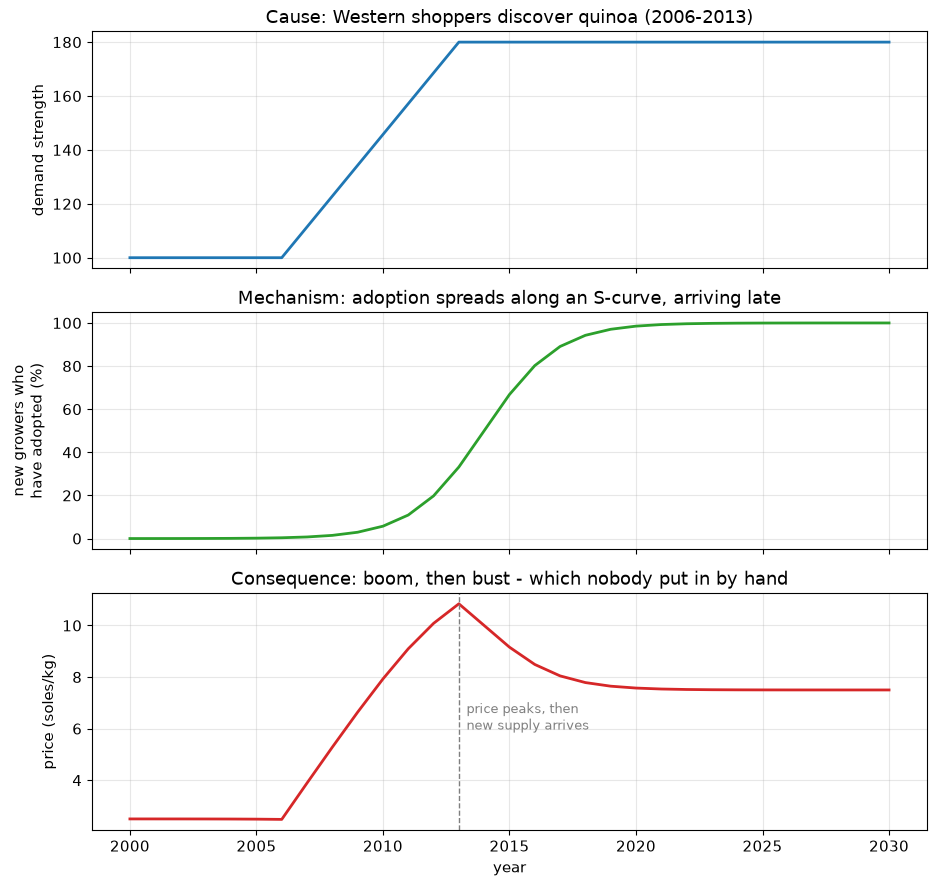

Price peaks in 2013 at 10.8, having started at 2.5.
By 2030 it has fallen to 7.5 - still above the old level, but well off the peak.


In [8]:
# ---------------------------------------------------------------------------
# MODEL 3: logistic adoption by new producers, feeding into the market
# ---------------------------------------------------------------------------

years3 = np.arange(2000, 2031)

# --- Demand side: a gradual ramp rather than Model 2's sudden jump -----------
DEMAND_START, DEMAND_END = 100.0, 180.0    # demand intercept before and after
RAMP_FROM,   RAMP_TO     = 2006, 2013      # the years over which shoppers discover quinoa

def demand_intercept_ramp(year):
    if year < RAMP_FROM:
        return DEMAND_START
    if year > RAMP_TO:
        return DEMAND_END
    # In between, slide linearly from start to end.
    fraction_done = (year - RAMP_FROM) / (RAMP_TO - RAMP_FROM)
    return DEMAND_START + (DEMAND_END - DEMAND_START) * fraction_done

# --- Supply side: the S-curve of new entrants -------------------------------
SPREAD_RATE   = 0.7      # "r": how fast adoption spreads
MIDPOINT_YEAR = 2014     # the year adoption is halfway done (its steepest moment)
EXPANSION     = 0.50     # if every potential entrant adopts, supply rises 50%
SUPPLY_FIXED  = 80.0     # quantity from established Andean growers

def adopted_fraction(year):
    # This is the closed-form solution of the logistic equation, which saves us
    # a loop. It rises smoothly from ~0 to 1 with its steepest point at MIDPOINT_YEAR.
    return 1.0 / (1.0 + np.exp(-SPREAD_RATE * (year - MIDPOINT_YEAR)))

# --- Run it ------------------------------------------------------------------
adoption, quantity, price = [], [], []

for year in years3:
    A = adopted_fraction(year)                     # how far adoption has spread
    Q = SUPPLY_FIXED * (1.0 + EXPANSION * A)       # total world supply this year
    a = demand_intercept_ramp(year)                # how keen buyers are this year
    p = (a - Q) / DEMAND_SLOPE                     # the price that clears the market
    adoption.append(A); quantity.append(Q); price.append(p)

adoption = np.array(adoption); quantity = np.array(quantity); price = np.array(price)

# --- Draw three stacked panels: cause, mechanism, consequence ----------------
fig, axes = plt.subplots(3, 1, figsize=(9.5, 9), sharex=True)

axes[0].plot(years3, [demand_intercept_ramp(y) for y in years3], linewidth=2, color="tab:blue")
axes[0].set_ylabel("demand strength")
axes[0].set_title("Cause: Western shoppers discover quinoa (2006-2013)")

axes[1].plot(years3, 100 * adoption, linewidth=2, color="tab:green")
axes[1].set_ylabel("new growers who\nhave adopted (%)")
axes[1].set_title("Mechanism: adoption spreads along an S-curve, arriving late")

axes[2].plot(years3, price, linewidth=2, color="tab:red")
axes[2].axvline(2013, color="tab:grey", linestyle="--", linewidth=1)
axes[2].set_ylabel("price (soles/kg)")
axes[2].set_xlabel("year")
axes[2].set_title("Consequence: boom, then bust - which nobody put in by hand")
axes[2].text(2013.3, price.max() * 0.55, "price peaks, then\nnew supply arrives", fontsize=9, color="tab:grey")

plt.tight_layout()
plt.show()

peak_year = years3[price.argmax()]
print("Price peaks in %d at %.1f, having started at %.1f." % (peak_year, price.max(), price[0]))
print("By %d it has fallen to %.1f - still above the old level, but well off the peak." % (years3[-1], price[-1]))

## What to notice

**The bust is not a separate event.** In this model the crash has the same cause as the boom. The high price is what made quinoa worth planting in Arequipa and Nepal; the planting is what ended the high price. There is no second shock, no policy failure, no villain. A system whose response to a signal destroys the signal is a **negative feedback loop with a delay**, and it is one of the two or three most common structures in all of social science.

**Two models, one observation.** Model 2 and Model 3 both produce "price rises, then falls." They attribute it to completely different mechanisms: a planting lag among existing farmers, versus entry by new ones. Given only a price chart you *cannot* tell them apart. This is called **equifinality** or the identification problem, and it is the single most important idea in this notebook. Fitting a curve to data does not establish a mechanism. To choose between these two models you would need different evidence entirely — acreage by region, entry dates, who planted what and when.

**Notice what we did not model.** Where does `MIDPOINT_YEAR = 2014` come from? We chose it, partly so the picture would resemble the article. That is fine for illustration and fatal for inference. A more honest model would make adoption *respond* to the price rather than be scheduled by us (see the exercises), which is harder and much more interesting.

## Exercises

1. Set `EXPANSION = 1.0` — the new regions can double world supply rather than add half. What happens to the final price relative to the pre-boom price? What would that mean for a Puno farmer who took on debt in 2012?
2. Set `SPREAD_RATE = 0.25`. The crash becomes gentler and later. Which is worse for Andean farmers: a fast crash or a slow one? Notice that answering this requires a value judgement that the model does not contain.
3. **The interesting one.** Make adoption endogenous: instead of `adopted_fraction(year)`, grow `A` inside the loop using `A = A + r * A * (1 - A) * max(0, price_last_year - threshold)`. Now high prices *cause* adoption. You will need to keep track of last year's price. Does the boom-bust get sharper or smoother? This is the step from *describing* a pattern to *explaining* it.

---
# Model 4 
# Soil, llamas and the cost of a good decade: a stock-and-flow model

## The claim in the article

A study by Adam Drucker's student Enrico Avitabile found that more than half of surveyed Bolivian farmers said their soil was worse than before the boom, for two reasons. High prices pulled land out of fallow, which had been letting it rest, causing erosion and nutrient loss. And farmers who earned more from quinoa cut back their llama herds — so less manure was available to fertilise and protect the soil.

Read that again and notice its shape. It is a **loop**: quinoa area up, pasture down, llamas down, manure down, soil down, and soil is what quinoa grows in.

## The idea: stocks and flows

Model 1 to 3 tracked prices and quantities — things that happen in a year. This model tracks something different: a **stock**, a quantity that accumulates. Soil fertility is not an event, it is a bank balance. Each year some is deposited and some withdrawn, and what carries over is the balance.

$$\text{stock next year} = \text{stock this year} + \text{inflows} - \text{outflows}$$

Everything below is that one sentence, written three times. We track two stocks:

**Soil fertility** $S$ (an index, 1.0 = pre-boom condition):

$$S_{t+1} = S_t + \underbrace{g\,(1 - q_t)(S_{max} - S_t)}_{\text{resting land recovers}} + \underbrace{m\,L_t}_{\text{llama manure}} - \underbrace{k\, q_t}_{\text{cropping depletes}}$$

**The llama herd** $L$, which grows toward whatever the remaining pasture can support:

$$L_{t+1} = L_t + \rho\, L_t\left(1 - \frac{L_t}{K(1 - q_t)}\right)$$

That is the logistic equation from Model 3 again — but here it is doing a completely different job, describing a population pressing against a limit rather than an idea spreading. Reusing structure across domains is most of what modeling skill consists of.

And the two are linked through a single decision: $q_t$, the fraction of land planted with quinoa, which rises when the price rises. Every kilogram of land in quinoa is a kilogram not in pasture.

## What to watch for

A stock can be run down for years while every annual report looks excellent. That is the whole point of building this model.

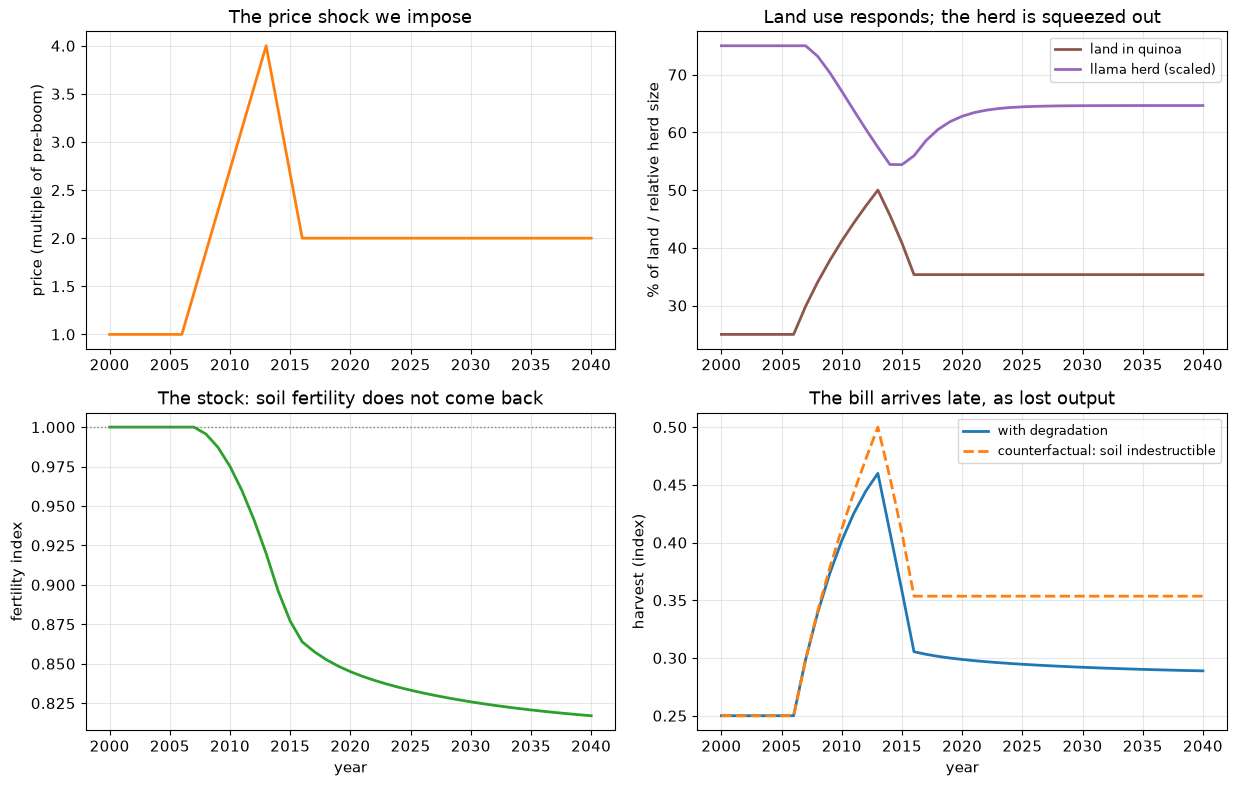

Soil fertility: 1.000 in 2000  ->  0.920 at the 2013 peak  ->  0.817 by 2040
Harvest in 2040: 0.289 with degradation vs 0.354 without - a shortfall of 18.3%.


In [9]:
# ---------------------------------------------------------------------------
# MODEL 4: coupled soil / herd / land-use dynamics
# ---------------------------------------------------------------------------

years4 = np.arange(2000, 2041)  # run well past the boom, to see the aftermath

# The price story, taken from the article: rise to 2013, fall by 2016
def relative_price(year):
    # Expressed as a multiple of the pre-boom price, so 1.0 = "normal", 4.0 = "quadrupled".
    if year < 2006:
        return 1.0
    if year <= 2013:
        return 1.0 + 3.0 * (year - 2006) / 7.0      # climb from 1x to 4x
    if year <= 2016:
        return 4.0 - 2.0 * (year - 2013) / 3.0      # fall from 4x to 2x
    return 2.0                                       # settle at twice pre-boom

# Parameters 
REGEN     = 0.10      # "g":   how fast resting (fallow) land rebuilds fertility
MANURE    = 0.0225    # "m":   fertility added per unit of llama herd
DEPLETION = 0.09      # "k":   fertility removed per unit of land cropped
HERD_GROW = 0.35      # "rho": how fast the herd grows toward what pasture allows
S_MAX     = 1.0       # the best the soil gets: its pristine pre-boom condition
BASE_AREA = 0.25      # fraction of land in quinoa at the normal price
RESPONSE  = 0.5       # how strongly planting responds to price (0.5 = square-root)

# These parameters are deliberately tuned so that at the pre-boom price the
# system sits STILL: inflows exactly balance outflows, soil stays at 1.0, herd
# stays at 1.0. That matters. It means anything we see later was caused by the
# boom and not by a slow drift we accidentally built in. Always establish that
# your model does nothing before you ask it to do something.

def planted_fraction(price):
    # Farmers plant more when the price is high, with diminishing enthusiasm,
    # and can never plant more than 85% of their land.
    return min(0.85, BASE_AREA * price ** RESPONSE)

def run_soil_model(soil_can_degrade=True):
    # If soil_can_degrade is False we hold fertility fixed at 1.0. That gives us
    # a COUNTERFACTUAL: the same boom in a world where soil were indestructible.
    # Comparing the two isolates the cost of degradation.
    soil, herd = 1.0, 1.0
    history = []

    for year in years4:
        price = relative_price(year)
        q = planted_fraction(price)          # land in quinoa
        pasture = 1.0 - q                    # land left for llamas
        yield_per_unit = soil                # fertile soil grows more per hectare
        harvest = q * yield_per_unit         # this year's output
        history.append({"year": year, "price": price, "area": q,
                        "soil": soil, "herd": herd, "harvest": harvest})

        # Update the two stocks: balance = balance + in - out 
        if soil_can_degrade:
            recovery  = REGEN * pasture * (S_MAX - soil)   # resting land rebuilds
            fertiliser = MANURE * herd                     # manure from llamas
            loss      = DEPLETION * q                      # cropping takes nutrients
            soil = min(S_MAX, max(0.05, soil + recovery + fertiliser - loss))

        capacity = max(pasture / (1.0 - BASE_AREA), 1e-6)   # pasture sets the ceiling
        herd = max(0.02, herd + HERD_GROW * herd * (1.0 - herd / capacity))

    return history

with_degradation    = run_soil_model(soil_can_degrade=True)
without_degradation = run_soil_model(soil_can_degrade=False)

# Pull each column out of the history so it is easy to plot.
def column(history, key):
    return np.array([row[key] for row in history])

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8))

axes[0, 0].plot(years4, column(with_degradation, "price"), linewidth=2, color="tab:orange")
axes[0, 0].set_title("The price shock we impose")
axes[0, 0].set_ylabel("price (multiple of pre-boom)")

axes[0, 1].plot(years4, 100 * column(with_degradation, "area"), linewidth=2, color="tab:brown", label="land in quinoa")
axes[0, 1].plot(years4, 100 * column(with_degradation, "herd") * (1 - BASE_AREA), linewidth=2,
                color="tab:purple", label="llama herd (scaled)")
axes[0, 1].set_title("Land use responds; the herd is squeezed out")
axes[0, 1].set_ylabel("% of land / relative herd size")
axes[0, 1].legend(fontsize=9)

axes[1, 0].plot(years4, column(with_degradation, "soil"), linewidth=2, color="tab:green")
axes[1, 0].axhline(1.0, color="tab:grey", linestyle=":", linewidth=1)
axes[1, 0].set_title("The stock: soil fertility does not come back")
axes[1, 0].set_ylabel("fertility index")
axes[1, 0].set_xlabel("year")

axes[1, 1].plot(years4, column(with_degradation, "harvest"), linewidth=2, label="with degradation")
axes[1, 1].plot(years4, column(without_degradation, "harvest"), linewidth=2, linestyle="--",
                label="counterfactual: soil indestructible")
axes[1, 1].set_title("The bill arrives late, as lost output")
axes[1, 1].set_ylabel("harvest (index)")
axes[1, 1].set_xlabel("year")
axes[1, 1].legend(fontsize=9)

plt.tight_layout()
plt.show()

s = column(with_degradation, "soil")
h_with, h_without = column(with_degradation, "harvest"), column(without_degradation, "harvest")
print("Soil fertility: 1.000 in 2000  ->  %.3f at the 2013 peak  ->  %.3f by 2040" % (s[13], s[-1]))
print("Harvest in 2040: %.3f with degradation vs %.3f without - a shortfall of %.1f%%."
      % (h_with[-1], h_without[-1], 100 * (1 - h_with[-1] / h_without[-1])))

## What to notice

**Every single year of the boom looks like a success.** Output rises, income rises, and it is all true. Meanwhile the stock is being drawn down, invisibly, because a stock is not in this year's accounts. This model does not contradict the good news from Model 1 — it says the good news was measured over the wrong horizon. That combination, "the short-run finding is right *and* the long-run picture is bad," is far more common in social science than either side of most public arguments admits.

**Nothing recovers on its own.** When the price falls back to twice pre-boom levels, land use partly reverts and the herd partly recovers, but fertility settles at a permanently lower level. Stocks have memory. This is called **hysteresis**: the system does not retrace its path when you undo the shock. It is why "we can always reverse the policy later" is often a false promise.

**The loop is the finding.** Any one of the three links — more quinoa, fewer llamas, less manure — is unremarkable on its own. Together they form a circuit that amplifies. You could not have found this by staring at correlations between pairs of variables; you find it by drawing the arrows and following them round.

**Be honest about the parameters.** `DEPLETION = 0.09` is not measured; nobody handed us that number. So the *magnitudes* in these figures mean nothing. What survives is the qualitative shape: delayed, partly irreversible decline that a boom-time income statement cannot see. Report the shape, not the digits.

## Exercises

1. Set `MANURE = 0.0` — imagine the herds vanish entirely. How much worse does the soil get? This is a crude way of asking how much of the damage runs through the llama channel rather than through fallow loss, and it is the kind of question a field study could then go and test.
2. Add a policy. Cap `planted_fraction` at 0.4 by changing the `min(0.85, ...)`. The farmer earns less during the boom and has better soil afterwards. Was the cap worth it? Notice you cannot answer without deciding how much you care about the future relative to the present — a **discount rate**, and a moral choice wearing a technical costume.
3. Extend the model so that the *price* also depends on total harvest, linking this to Model 2. You will have created a feedback loop with two delays. Predict before you run it whether that makes the system more or less stable.

---
# Model 5  
# Why 3,000 varieties become five: a public-goods game

## The claim in the article

Export demand fastened onto a handful of the roughly 3,000 quinoa varieties, so farmers abandoned many of the rest. Stefano Padulosi argues those abandoned varieties are precisely what quinoa will need in order to adapt to pressures like climate change, and would like to see a global mechanism that rewards Andean farmers for maintaining diversity. Meanwhile Adam Drucker has run pilot studies on what it would take to persuade farmers to keep growing varieties exporters do not want — and Gitter and Bellemare found that the 150 Puno farmers they interviewed would grow less-preferred varieties in exchange for cash.

## The idea

Models 1 to 4 had no *strategy* in them. Prices moved and people responded. But this is a different kind of problem, because the value of diversity does not accrue to the farmer who maintains it. A rare variety that turns out to carry drought resistance benefits quinoa growers everywhere, for decades, including ones not yet born. The farmer who kept it alive captures almost none of that.

This is the structure of a **public good**: costly to provide individually, valuable to everyone collectively, and therefore under-provided. It is the same skeleton as vaccination, tax compliance, fisheries, and emissions.

## Part A: two farmers, four outcomes

Strip it to two farmers, each choosing **Export variety** (high price) or **Traditional variety** (lower price, but adds to the shared stock of diversity):

$$\text{payoff} = \underbrace{\text{private revenue from your own choice}}_{\text{yours alone}} + \underbrace{\text{value of diversity}}_{\text{shared by all, whoever provides it}}$$

Watch what happens when each farmer asks the only question a payoff matrix lets them ask: *given whatever the other one does, what is best for me?*

In [10]:
# ---------------------------------------------------------------------------
# MODEL 5A: the two-farmer diversity game
# ---------------------------------------------------------------------------

# --- Parameters -------------------------------------------------------------
REVENUE_EXPORT      = 100.0   # what you earn growing the variety exporters want
REVENUE_TRADITIONAL = 70.0    # what you earn growing an old local variety
DIVERSITY_VALUE     = 20.0    # value created for EVERYONE by each conserving farmer
# Note the tension deliberately built into these three numbers: conserving costs
# you 30 privately but creates 20 of value for EACH of the two farmers, i.e. 40
# in total. So conserving is good for the pair (40 > 30) and bad for you (20 < 30).

def payoff(my_choice, other_choice):
    # My private revenue depends only on my own choice.
    private = REVENUE_TRADITIONAL if my_choice == "Traditional" else REVENUE_EXPORT
    # The public benefit depends on how many of us conserve - mine and theirs alike.
    conservers = (my_choice == "Traditional") + (other_choice == "Traditional")
    public = DIVERSITY_VALUE * conservers
    return private + public

choices = ["Export", "Traditional"]

print("Payoffs (Farmer A, Farmer B). Rows = A's choice, columns = B's choice.\n")
print("%-14s %22s %22s" % ("", "B: Export", "B: Traditional"))
for a in choices:
    row = ""
    for b in choices:
        row += "%22s " % ("(%.0f, %.0f)" % (payoff(a, b), payoff(b, a)))
    print("%-14s %s" % ("A: " + a, row))

# --- Find the Nash equilibrium ----------------------------------------------
# Definition: a pair of choices where NEITHER farmer can do better by switching,
# taking the other's choice as fixed. Let us just check all four possibilities.
print("\nChecking each outcome for stability:")
for a in choices:
    for b in choices:
        other_a = [c for c in choices if c != a][0]     # A's alternative
        other_b = [c for c in choices if c != b][0]     # B's alternative
        a_content = payoff(a, b) >= payoff(other_a, b)  # would A rather switch?
        b_content = payoff(b, a) >= payoff(other_b, a)  # would B rather switch?
        verdict = "NASH EQUILIBRIUM - nobody wants to move" if (a_content and b_content) else "unstable"
        print("  A=%-12s B=%-12s -> total welfare %5.0f   %s"
              % (a, b, payoff(a, b) + payoff(b, a), verdict))

both_export = payoff("Export", "Export") + payoff("Export", "Export")
both_conserve = payoff("Traditional", "Traditional") + payoff("Traditional", "Traditional")
print("\nEveryone growing export varieties yields total welfare of %.0f." % both_export)
print("Everyone conserving would yield %.0f - which is %.0f higher, and unreachable."
      % (both_conserve, both_conserve - both_export))

Payoffs (Farmer A, Farmer B). Rows = A's choice, columns = B's choice.

                            B: Export         B: Traditional
A: Export                  (100, 100)              (120, 90) 
A: Traditional              (90, 120)             (110, 110) 

Checking each outcome for stability:
  A=Export       B=Export       -> total welfare   200   NASH EQUILIBRIUM - nobody wants to move
  A=Export       B=Traditional  -> total welfare   210   unstable
  A=Traditional  B=Export       -> total welfare   210   unstable
  A=Traditional  B=Traditional  -> total welfare   220   unstable

Everyone growing export varieties yields total welfare of 200.
Everyone conserving would yield 220 - which is 20 higher, and unreachable.


### What just happened

Growing the export variety is a **dominant strategy**: it is better for you no matter what your neighbour does. So both farmers do it, and they land on the outcome that is worse for both. Nobody was greedy, short-sighted or ignorant. Each did the best available thing, and the aggregate was bad. That gap between individually sensible and collectively good is the reason this class of model exists — and it is why the article's talk of a "global mechanism" is not hand-waving but a structural necessity. Exhortation cannot fix a dominant strategy. Changing the payoffs can.

Which raises the practical question Drucker went out and asked: **how much cash would it take?**

## Part B: paying for conservation

Farmers differ. Some are almost indifferent between varieties; others would need a great deal to give up export revenue. Each farmer has a **willingness to accept** — the smallest payment that would make conserving worth it. A farmer conserves if the payment offered is at least their willingness to accept.

Below we simulate 150 farmers, matching the 150 Puno farmers in the Gitter and Bellemare interviews, and ask a designer's question: what does it cost to protect a target share of varieties? Then we compare two ways of paying, which turns out to matter a great deal.

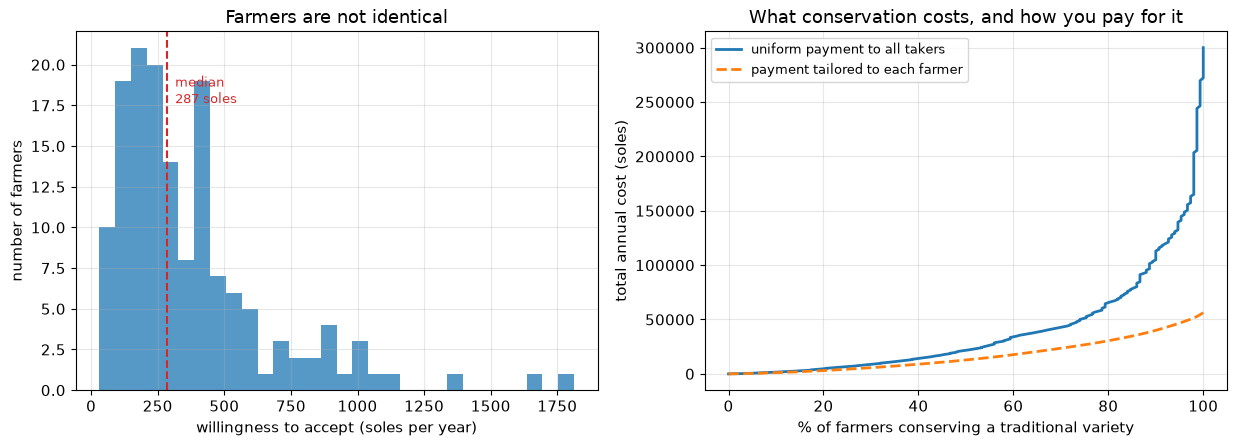

To get 60% of farmers conserving:
  offer                   :    381 soles per farmer per year
  cost, uniform payment   :  34667 soles per year
  cost, tailored payment  :  18011 soles per year
  overpayment ('rent')    :  16656 soles, or 48% of the uniform bill


In [11]:
# ---------------------------------------------------------------------------
# MODEL 5B: how much would conservation cost?
# ---------------------------------------------------------------------------

N_FARMERS = 150     # matching the interview sample size mentioned in the article

# Each farmer's willingness to accept, in soles per year. We use a lognormal
# distribution: most farmers cheap, a few very expensive, none negative. That
# right-skewed shape is typical of real willingness-to-accept data, and choosing
# it is itself a modeling assumption you should be prepared to defend.
wta = RNG.lognormal(mean=np.log(300), sigma=0.8, size=N_FARMERS)

payments = np.linspace(0, 2000, 400)     # 400 candidate payment levels to test

uptake, cost_uniform, cost_targeted = [], [], []

for offer in payments:
    conserving = wta <= offer                      # True/False for each farmer
    n_conserving = conserving.sum()                # True counts as 1
    uptake.append(100 * n_conserving / N_FARMERS)

    # Way 1 - UNIFORM: advertise one price and pay it to everyone who accepts.
    # Simple, transparent, and you overpay every farmer who would have said yes
    # for less. That overpayment is called "rent".
    cost_uniform.append(offer * n_conserving)

    # Way 2 - TARGETED: pay each farmer exactly their own willingness to accept.
    # Cheaper, but it requires knowing a private number, which is precisely what
    # auctions and pilot schemes are trying to discover.
    cost_targeted.append(wta[conserving].sum())

uptake = np.array(uptake)
cost_uniform = np.array(cost_uniform)
cost_targeted = np.array(cost_targeted)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))

ax1.hist(wta, bins=30, color="tab:blue", alpha=0.75)
ax1.axvline(np.median(wta), color="tab:red", linestyle="--")
ax1.text(np.median(wta) * 1.1, ax1.get_ylim()[1] * 0.8,
         "median\n%.0f soles" % np.median(wta), color="tab:red", fontsize=9)
ax1.set_xlabel("willingness to accept (soles per year)")
ax1.set_ylabel("number of farmers")
ax1.set_title("Farmers are not identical")

ax2.plot(uptake, cost_uniform, linewidth=2, label="uniform payment to all takers")
ax2.plot(uptake, cost_targeted, linewidth=2, linestyle="--", label="payment tailored to each farmer")
ax2.set_xlabel("% of farmers conserving a traditional variety")
ax2.set_ylabel("total annual cost (soles)")
ax2.set_title("What conservation costs, and how you pay for it")
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

# What does it cost to reach a 60% conservation target?
target = 60.0
i = int(np.argmax(uptake >= target))   # the first payment level that reaches the target
print("To get %.0f%% of farmers conserving:" % target)
print("  offer                   : %6.0f soles per farmer per year" % payments[i])
print("  cost, uniform payment   : %6.0f soles per year" % cost_uniform[i])
print("  cost, tailored payment  : %6.0f soles per year" % cost_targeted[i])
print("  overpayment ('rent')    : %6.0f soles, or %.0f%% of the uniform bill"
      % (cost_uniform[i] - cost_targeted[i],
         100 * (cost_uniform[i] - cost_targeted[i]) / cost_uniform[i]))

## What to notice

**The cost curve bends upward.** The first farmers are cheap, the last are dear, because you must raise the offer to reach the reluctant and that raise goes to everybody. So "conserve all 3,000 varieties" and "conserve most varieties" have wildly different price tags. Targets should be chosen with the cost curve in hand, not before.

**How you pay can matter as much as how much.** The gap between the two lines is money that buys no additional conservation. In practice this is why conservation schemes experiment with auctions, in which farmers bid and the cheapest bids win — an attempt to move from the upper line toward the lower one. The article's mention of pilot studies to work out what incentives farmers need is exactly this: not charity, but measurement of a distribution you cannot observe directly.

**The article's ending now reads differently.** Drucker says the approach works and is cost-effective, and that the obstacle is unlocking public funds. Our model says why the obstacle exists: the beneficiaries are global and future, while the payers would be national and present. The mismatch is not a failure of will. It is in the structure of the payoffs.

**A caution about the numbers.** Our 150 willingness-to-accept values came from a random number generator, not from Puno. The *shape* of the argument is robust; the soles are fiction. Never let a simulated distribution be quoted as a finding.

## Exercises

1. Change `sigma=0.8` to `sigma=0.3`, making farmers much more alike. What happens to the gap between uniform and tailored payment? Explain why heterogeneity is the thing that makes payment design matter.
2. In Part A, raise `DIVERSITY_VALUE` to 40 and lower `REVENUE_EXPORT` to 75. Does conserving become the dominant strategy? What real-world change would correspond to that shift in parameters?
3. The article mentions creating internal markets for threatened varieties, in hospital and school food programmes. Which parameter of Part A does that intervention change, and how does it differ from simply paying farmers?

---
# Model 6 

# When a model fails usefully: demand with a subsistence floor

## The claim in the article

Andrew Stevens found that across Peru as a whole, quinoa eating fell from about 6.07 kg per person per year in 2004 to about 4.09 kg in 2012, following the price. But in Puno — where more than 80% of Peru's quinoa is grown, and where prices rose even more steeply than nationally — people ate slightly *more*: about 23.62 kg against 22.22 kg. Stevens reports that Puno households did not cut back despite a roughly fourfold price increase.

Consumption rising while the price quadruples is the kind of fact that breaks textbook models. Good. This model is included because it **fails**, and because the failure is more instructive than any of the successes above.

## Start with the standard model

The simplest respectable demand model says people spend a fixed share $\alpha$ of their budget $m$ on quinoa. Then the quantity bought is

$$q = \frac{\alpha\, m}{p}$$

Quadruple the price, and consumption falls to a quarter. That is a strong prediction, and we can check it directly against Stevens's national numbers.

## Then relax one assumption

Now suppose there is some quantity of quinoa a household will hold onto almost regardless of price — because it is what the children eat, because it is what the dishes require, because it is what food *is* there. Call it $\gamma$, a habitual or subsistence floor. The household secures $\gamma$ first, then spends a share of whatever is left over the usual way:

$$q = \gamma + \frac{\alpha}{p}\bigl(m - p\,\gamma\bigr)$$

This is the **Stone–Geary** demand function, and it turns "quinoa is culturally important" from a piece of atmosphere into a number you can estimate and argue about. If $\gamma = 0$ it collapses back to the standard model, which is a good sign: a useful generalisation should contain the thing it generalises.

We will do two things: find the floor that reproduces the national fall, then try to find one that reproduces the Puno rise.

In [12]:
# ---------------------------------------------------------------------------
# MODEL 6: fitting a subsistence floor to Stevens's two findings
# ---------------------------------------------------------------------------

# --- The observations from the article --------------------------------------
NATIONAL = {"name": "Peru as a whole", "q_2004": 6.07,  "q_2012": 4.09,  "budget_share": 0.005}
PUNO     = {"name": "Puno region",     "q_2004": 22.22, "q_2012": 23.62, "budget_share": 0.040}

PRICE_2004 = 2.0     # soles per kilogram (an arbitrary but harmless scale)
PRICE_2012 = 8.0     # the roughly fourfold increase the article reports
INCOME_GROWTH = 1.40 # Peruvian living standards rose over this period; the article
                     # notes all three household groups saw their welfare rise.

def stone_geary_prediction(floor, q_start, price_start, price_end, budget_start, budget_end):
    # Step 1: work out the household's marginal budget share "alpha" from the
    # fact that it consumed q_start when the price was price_start. This is
    # called CALIBRATION: we do not guess alpha, we solve for the value that
    # makes the model exactly reproduce the starting point.
    spare_budget = budget_start - price_start * floor      # money left after the floor
    if spare_budget <= 0 or q_start <= floor:
        return np.nan                                     # this floor is impossible
    alpha = (q_start - floor) * price_start / spare_budget

    # Step 2: with alpha fixed, predict consumption at the new price and income.
    spare_later = budget_end - price_end * floor
    if spare_later <= 0:
        return np.nan
    return floor + (alpha / price_end) * spare_later

def analyse(region):
    # Recover the household budget from the budget share quoted in the article.
    budget_2004 = region["q_2004"] * PRICE_2004 / region["budget_share"]
    budget_2012 = budget_2004 * INCOME_GROWTH

    # First: the standard model, i.e. a floor of exactly zero.
    plain = stone_geary_prediction(0.0, region["q_2004"], PRICE_2004, PRICE_2012,
                                   budget_2004, budget_2012)

    # Then: try every floor from 0 up to just below what they already eat, and
    # see which one comes closest to the observed 2012 figure. This is a "grid
    # search" - the least clever and most transparent way to fit a parameter.
    floors = np.linspace(0.0, region["q_2004"] * 0.999, 2000)
    predictions = np.array([stone_geary_prediction(f, region["q_2004"], PRICE_2004,
                                                   PRICE_2012, budget_2004, budget_2012)
                            for f in floors])
    errors = np.abs(predictions - region["q_2012"])
    best = np.nanargmin(errors)          # the floor with the smallest error

    return {"region": region, "budget_2004": budget_2004, "plain": plain,
            "floors": floors, "predictions": predictions, "errors": errors,
            "best_floor": floors[best], "best_prediction": predictions[best],
            "best_error": errors[best]}

national, puno = analyse(NATIONAL), analyse(PUNO)

for res in (national, puno):
    r = res["region"]
    print("=" * 66)
    print(r["name"])
    print("  observed 2004 -> 2012            : %.2f -> %.2f kg per person" % (r["q_2004"], r["q_2012"]))
    print("  standard model (no floor) predicts: %.2f kg" % res["plain"])
    print("  best-fitting floor               : %.2f kg, predicting %.2f kg"
          % (res["best_floor"], res["best_prediction"]))
    print("  remaining error                  : %.2f kg" % res["best_error"])
print("=" * 66)

Peru as a whole
  observed 2004 -> 2012            : 6.07 -> 4.09 kg per person
  standard model (no floor) predicts: 2.12 kg
  best-fitting floor               : 3.03 kg, predicting 4.09 kg
  remaining error                  : 0.00 kg
Puno region
  observed 2004 -> 2012            : 22.22 -> 23.62 kg per person
  standard model (no floor) predicts: 7.78 kg
  best-fitting floor               : 22.20 kg, predicting 22.20 kg
  remaining error                  : 1.42 kg


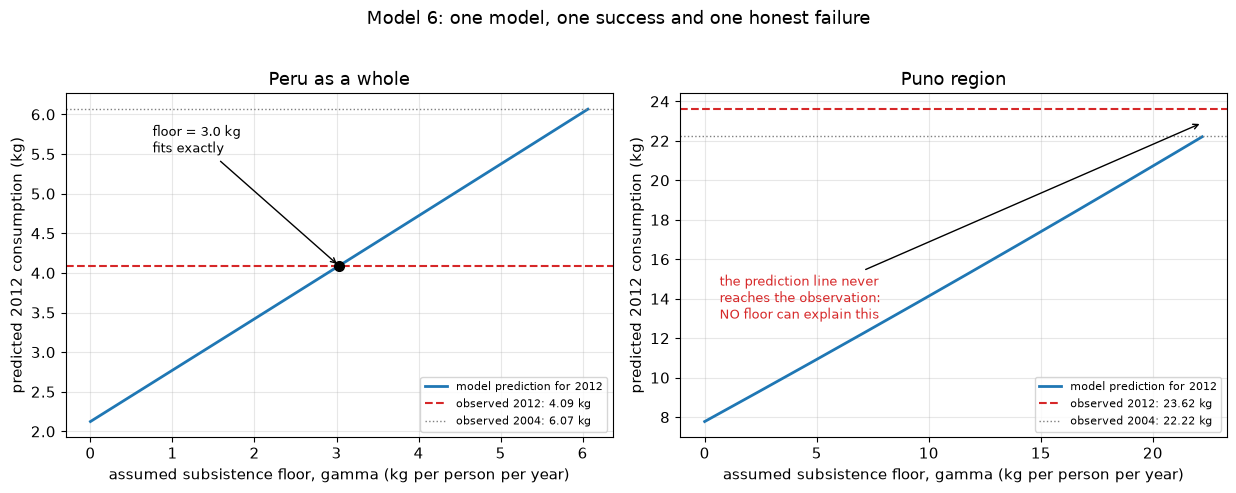

In [13]:
# ---------------------------------------------------------------------------
# Draw the fit for each region: how close can the model get, for any floor?
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

for ax, res in zip(axes, (national, puno)):
    r = res["region"]
    ax.plot(res["floors"], res["predictions"], linewidth=2, label="model prediction for 2012")
    ax.axhline(r["q_2012"], color="tab:red", linestyle="--", linewidth=1.5,
               label="observed 2012: %.2f kg" % r["q_2012"])
    ax.axhline(r["q_2004"], color="tab:grey", linestyle=":", linewidth=1,
               label="observed 2004: %.2f kg" % r["q_2004"])

    # Mark the best fit only if the model can actually get close.
    if res["best_error"] < 0.15:
        ax.plot(res["best_floor"], res["best_prediction"], "o", color="black", markersize=7)
        ax.annotate("floor = %.1f kg\nfits exactly" % res["best_floor"],
                    xy=(res["best_floor"], res["best_prediction"]),
                    xytext=(res["best_floor"] * 0.25, res["best_prediction"] * 1.35),
                    arrowprops=dict(arrowstyle="->", linewidth=1), fontsize=9)
    else:
        # Point the arrow at the GAP: where the prediction line stops short.
        ax.annotate("the prediction line never\nreaches the observation:\nNO floor can explain this",
                    xy=(res["floors"][-1], 0.5 * (res["best_prediction"] + r["q_2012"])),
                    xytext=(res["floors"][-1] * 0.03, r["q_2012"] * 0.55),
                    arrowprops=dict(arrowstyle="->", linewidth=1), fontsize=9, color="tab:red")

    ax.set_xlabel("assumed subsistence floor, gamma (kg per person per year)")
    ax.set_ylabel("predicted 2012 consumption (kg)")
    ax.set_title(r["name"])
    ax.legend(fontsize=8, loc="lower right")

plt.suptitle("Model 6: one model, one success and one honest failure", y=1.02)
plt.tight_layout()
plt.show()

## What to notice

**The standard model gets the national direction right and the magnitude badly wrong.** It predicts consumption collapsing to roughly a third of what was actually observed. Directionally correct, quantitatively useless — a distinction worth insisting on, because a great deal of published social science stops at the direction.

**A floor of about 3 kg per person fits the national data exactly.** That is a real finding of sorts: it converts the vague phrase "culturally important" into "roughly 3 kg a year that Peruvians will not give up." Now it is a claim someone can go and test against other evidence, which is the entire point of writing a model down.

**And for Puno, no floor works at all.** Look at the right-hand panel. As the assumed floor rises, the prediction climbs toward the 2004 level and stops — it can approach 22.22 kg and never exceed it. But Puno ate *more* in 2012 than in 2004. The gap does not shrink to zero for any parameter value. **The model is not mis-calibrated; it is mis-specified.** No amount of fitting will save it.

That is a genuinely valuable result, and here is why. When a model can be tuned to match anything, matching tells you nothing. This one *cannot* match, which means it has real content, and its failure points at specific missing mechanisms:

1. **Puno households are producers.** Their income rises *with* the quinoa price, in exactly the way Model 1 described. Our model treated income as independent of price, which is wrong precisely where quinoa is grown.
2. **Other prices moved too.** The article reports a hint that Puno households cut back on high-fat foods to keep eating quinoa. A one-good model cannot represent substitution *between* foods, and substitution is evidently what happened.
3. **Much of it was never bought.** Farmers eat their own harvest. What a market price means for a household that grows the good is a genuinely difficult question in survey economics, and our model quietly assumed every kilogram was purchased at the market price.

A one-good, fixed-income model was never going to survive contact with a region that grows 80% of the crop. Discovering that by watching it fail, rather than by being told, is the lesson.

## Exercises

1. Set `INCOME_GROWTH = 1.0` (no rise in living standards) and re-run. How much of the national story was price and how much was income? This is a **decomposition**, and it is one of the most common things applied modelers do.
2. Modify `analyse` so that for Puno the 2012 budget also includes quinoa sales revenue, which rises with the price: add something like `+ 100 * PRICE_2012` to `budget_2012`. Can the model now reproduce the Puno increase? What have you had to assume about how much they sell?
3. **A conceptual question.** We rejected the model because it could not fit. But we chose the fourfold price rise, the 40% income growth, and the budget shares ourselves. How would you distinguish "the model is wrong" from "our inputs are wrong"? There is no fully satisfying answer, and knowing that is important.

---
# Model 7  

# Modeling the story itself: how a false claim travelled

## The claim in the article

The article's own framing is that scary media reports circulated, and that even when people working on the ground tried to explain that buying quinoa was helping Andean farmers, what they had was anecdote rather than evidence. The evidence arrived years later, in working papers using ten years of ENAHO data.

For a course in *computational social science*, this is the most interesting model in the notebook — because the object being modeled is the discourse, not the market.

## The idea

A claim spreading through a population behaves much like an infection. At any moment, divide people into three groups:

- **S** — has not encountered the claim yet
- **B** — encountered it, believes it, repeats it to others
- **R** — has stopped repeating it, whether from boredom or from having seen the correction

The flows between them:

$$
\begin{aligned}
\text{new believers} &= \beta \, S \, B \quad \text{(a believer meets a susceptible)} \\
\text{people who drop it} &= \delta \, B
\end{aligned}
$$

The product $S \times B$ is the crucial term. It says transmission needs *both* someone to spread and someone to spread to — the same structure as the logistic in Models 3 and 4, now doing a third job. If you have followed this notebook you have now seen one mathematical form model an idea spreading, a herd of llamas hitting a limit, and a rumour propagating. That transferability is not a coincidence and it is not a trick; it is the reason formal modeling earns its keep across fields that share no subject matter.

## The question worth asking

The article's implicit criticism is about *timing*: the claim ran unopposed for years before anyone checked. So we run the same epidemic twice, changing only when the correction arrives, and ask what the correction buys.

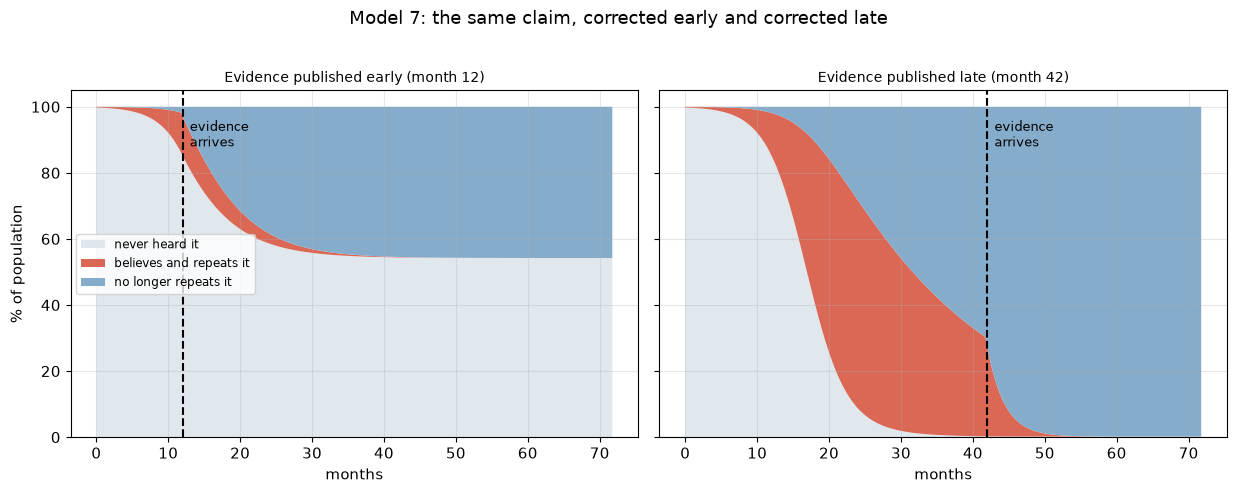

early correction  :  45.8% ever believed it | peak 12.0% believing at once, in month 12
late correction   :  99.8% ever believed it | peak 63.4% believing at once, in month 23


In [14]:
# ---------------------------------------------------------------------------
# MODEL 7: the spread of a claim, and the arrival of evidence
# ---------------------------------------------------------------------------

MONTHS = 72                 # six years, roughly 2010 to 2016
STEP = 0.25                 # we advance in quarter-month steps for smoothness

TRANSMISSION = 0.42         # "beta":  how readily the claim passes on
FORGETTING   = 0.05         # "delta": how fast people drop it unprompted
EVIDENCE_EFFECT = 8.0       # how much faster people drop it once evidence lands
SEED = 0.002                # the tiny fraction who believe it at the very start

def run_epidemic(evidence_month):
    # Three compartments, as fractions of the population, adding to 1.
    S, B, R = 1.0 - SEED, SEED, 0.0
    history = []
    t = 0.0

    while t < MONTHS:
        # Has the debunking evidence been published yet? If so, people abandon
        # the claim much faster. Note we model evidence as changing a RATE, not
        # as instantly convincing everyone - which is the realistic version.
        drop_rate = FORGETTING * (EVIDENCE_EFFECT if t >= evidence_month else 1.0)

        # The flows during this small slice of time.
        newly_convinced = TRANSMISSION * S * B * STEP
        newly_dropped   = drop_rate * B * STEP

        # Move people between compartments. Whatever leaves S enters B, and
        # whatever leaves B enters R. Nobody is created or destroyed - a useful
        # thing to check in any model of this kind.
        S = S - newly_convinced
        B = B + newly_convinced - newly_dropped
        R = R + newly_dropped

        history.append((t, S, B, R))
        t = t + STEP

    return np.array(history)

# Two worlds: evidence at 12 months, and evidence at 42 months.
early = run_epidemic(evidence_month=12)
late  = run_epidemic(evidence_month=42)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)

for ax, run, when, title in [(ax1, early, 12, "Evidence published early (month 12)"),
                             (ax2, late,  42, "Evidence published late (month 42)")]:
    t, S, B, R = run[:, 0], run[:, 1], run[:, 2], run[:, 3]
    ax.stackplot(t, 100 * S, 100 * B, 100 * R,
                 labels=["never heard it", "believes and repeats it", "no longer repeats it"],
                 colors=["#dfe6ec", "#d95f4c", "#7fa8c9"], alpha=0.95)
    ax.axvline(when, color="black", linestyle="--", linewidth=1.5)
    ax.text(when + 1, 88, "evidence\narrives", fontsize=9)
    ax.set_xlabel("months")
    ax.set_title(title, fontsize=10)

ax1.set_ylabel("% of population")
ax1.legend(loc="center left", fontsize=8.5)
plt.suptitle("Model 7: the same claim, corrected early and corrected late", y=1.02)
plt.tight_layout()
plt.show()

# How many people ever believed it? That is everyone who left S: 1 minus the
# fraction still in S at the end.
for name, run in [("early correction", early), ("late correction", late)]:
    ever = 100 * (1.0 - run[-1, 1])
    peak = 100 * run[:, 2].max()
    peak_month = run[run[:, 2].argmax(), 0]
    print("%-18s: %5.1f%% ever believed it | peak %4.1f%% believing at once, in month %.0f"
          % (name, ever, peak, peak_month))

## What to notice

**Correcting the record late barely reduces how many people ever believed it.** In the late-evidence world, almost everyone has already passed through the believing state before the papers appear. The correction changes what people believe *now*; it cannot change what they believed for three years, or the decisions they made meanwhile — the shoppers who stopped buying quinoa out of conscience, and whose purchases, on the evidence in the article, were helping the people they were worried about.

**Timing beats content.** This model has no term at all for how *convincing* the evidence is. It does not need one. The arrival date alone drives most of the difference. That is an uncomfortable result for anyone who believes better arguments win, and it is why "rapid response" and pre-registered data infrastructure are treated as serious epistemic institutions rather than public relations.

**The debunking never fully wins.** Notice that the pale grey "never heard it" band never disappears, and believers linger. In this model, as in reality, some people simply never encounter the correction. Retractions travel through a smaller network than the original claim.

**A caveat you should always attach to this model.** The epidemic analogy imports assumptions that may not hold for ideas: that everyone mixes with everyone, that believing is a single binary state, that hearing the correction is like recovering from an illness. Real beliefs are held in networks, with degrees of conviction, and with motivated resistance. The right response is not to abandon the model but to know which of its conclusions depend on the shaky assumptions. Here, "late corrections are weak" is robust across almost any variant. Specific percentages are not.

## Exercises

1. Find, by trial and error, the latest month at which the correction still keeps the eventual believer share under half. Is that a realistic timescale for academic publication? What would it take to hit it?
2. Set `EVIDENCE_EFFECT = 30`, making the debunking overwhelmingly persuasive, and keep it late. Compare to an early but weak correction (`evidence_month=12`, `EVIDENCE_EFFECT=2`). Which does better? What does that imply about where to invest?
3. **The hard one.** This model treats the true and false claims symmetrically — both are just claims that spread. Is there anything in the structure that would make truth spread better? If not, what does that suggest about relying on the marketplace of ideas?